# Experimental Results and Reproducibility Audit

**Research:** Cityscapes → Foggy Cityscapes object detection.

**Purpose:** Present previously obtained Standard AP50 checkpoint evaluations and document important comparability limitations. **This notebook does not train or evaluate any models.**

Run the short cells from top to bottom. The numerical results below are the verified values from the existing evidence summary.

## Cell 1 — Load analysis libraries and create the chart folder

In [2]:
%pip install pandas matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 86.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 129.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 292.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 265.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [matplotlib]6 [matplotlib]
Note: you may need to restart the kernel to use updated packages.


In [3]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

BASE = Path.cwd()
CHARTS = BASE / "charts"
CHARTS.mkdir(exist_ok=True)
print("Notebook folder:", BASE)

Notebook folder: /workspace/Adaptive_teacher_Experiment


## Cell 2 — Enter the Standard checkpoint evaluation results

AP50 is reported in percentage points. Each fog-level evaluation used 500 images and 10,412 Standard annotations.

In [4]:
results = pd.DataFrame({
    "Fog": ["Light", "Medium", "Strong"],
    "Source-only": [28.27, 24.37, 18.25],
    "Adaptive Teacher 0.80": [32.97, 31.22, 28.35],
    "Adaptive Teacher 0.70": [32.41, 30.78, 27.90],
    "Fog-Aware 05C": [32.58, 31.32, 27.79],
})
display(results)

,Fog,Source-only,Adaptive Teacher 0.80,Adaptive Teacher 0.70,Fog-Aware 05C
0,Light,28.27,32.97,32.41,32.58
1,Medium,24.37,31.22,30.78,31.32
2,Strong,18.25,28.35,27.90,27.79


## Cell 3 — Plot AP50 by fog level

Compare the four saved checkpoints. This is **not** a controlled causal comparison because the historical training datasets were not fully matched.

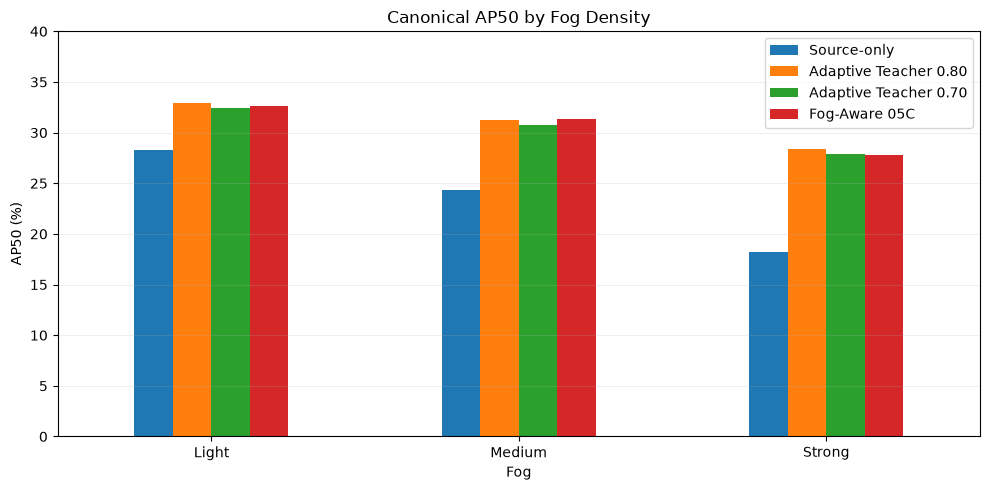

In [5]:
ax = results.set_index("Fog").plot.bar(figsize=(10, 5), rot=0)
ax.set(title="Standard AP50 by Fog Density", ylabel="AP50 (%)", ylim=(0, 40))
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.savefig(CHARTS / "01_ap50_comparison.png", dpi=200)
plt.show()

## Cell 4 — Visualize degradation as fog increases

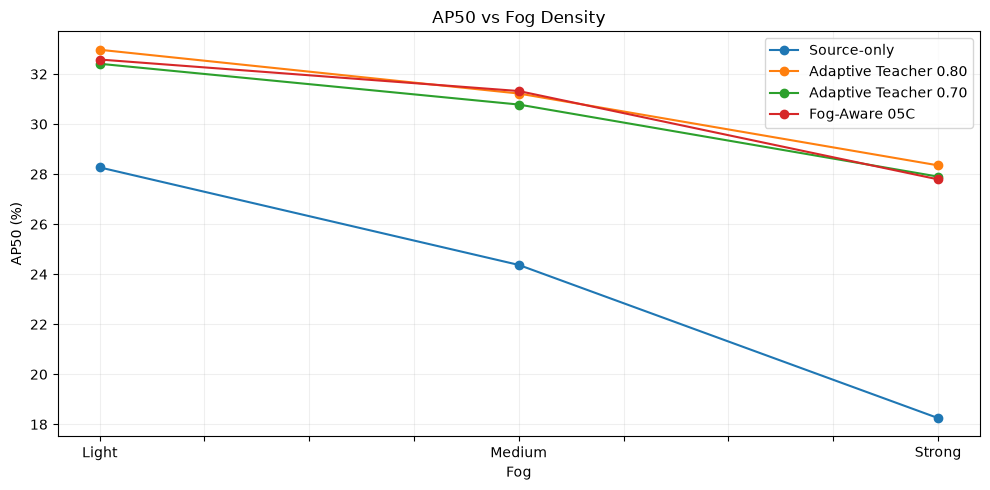

In [6]:
ax = results.set_index("Fog").plot.line(marker="o", figsize=(10, 5))
ax.set(title="AP50 vs Fog Density", ylabel="AP50 (%)")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(CHARTS / "02_fog_degradation.png", dpi=200)
plt.show()

## Cell 5 — Compute improvements over source-only

Values are **absolute AP50-point differences**, not percentage growth.

In [7]:
gains = results.set_index("Fog").drop(columns="Source-only").sub(
    results.set_index("Fog")["Source-only"], axis=0
)
display(gains.round(2))

,Adaptive Teacher 0.80,Adaptive Teacher 0.70,Fog-Aware 05C
Fog,,,
Light,4.70,4.14,4.31
Medium,6.85,6.41,6.95
Strong,10.10,9.65,9.54


## Cell 6 — Plot the AP50 improvements

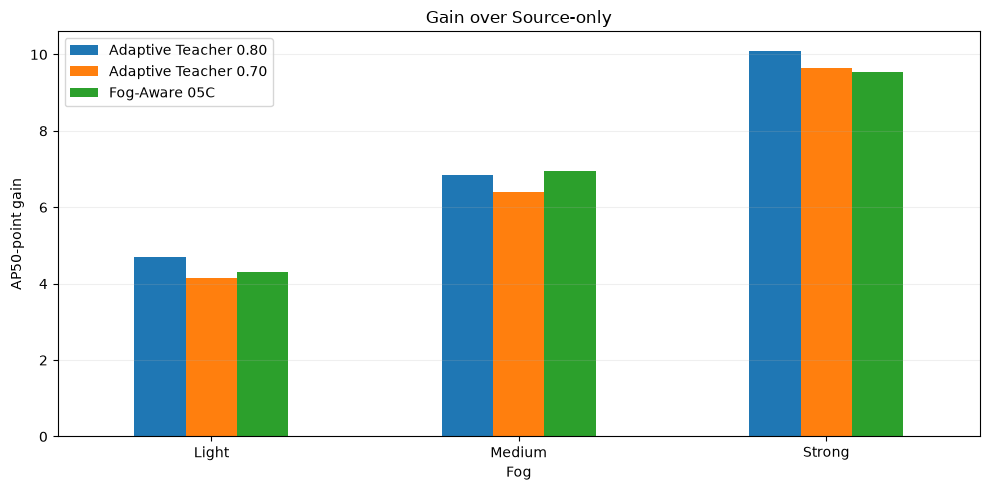

In [8]:
ax = gains.plot.bar(figsize=(10, 5), rot=0)
ax.set(title="Gain over Source-only", ylabel="AP50-point gain")
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.savefig(CHARTS / "03_gain_over_source.png", dpi=200)
plt.show()

## Cell 7 — Record Standard annotation counts

Historical raw count: 10,415; three degenerate boxes excluded; Standard valid count: 10,412. An earlier count of 10,658 has unresolved provenance.

In [9]:
annotation_audit = pd.DataFrame({
    "Measure": ["Raw annotations", "Degenerate boxes excluded", "Standard valid annotations", "Earlier unmatched count"],
    "Count": [10415, 3, 10412, 10658]
})
display(annotation_audit)

,Measure,Count
0,Raw annotations,10415
1,Degenerate boxes excluded,3
2,Canonical valid annotations,10412
3,Earlier unmatched count,10658


## Cell 8 — Record historical target-image mismatch

These are serialized target-image counts found in the historical training evidence. The exact fog composition of the 2,975-image run is unverified.

In [10]:
target_mix = pd.DataFrame({
    "Historical model": ["Adaptive Teacher 0.80", "Adaptive Teacher 0.70", "Fog-Aware 05C"],
    "Serialized target images": [2975, 8925, 8925]
})
display(target_mix)

,Historical model,Serialized target images
0,Adaptive Teacher 0.80,2975
1,Adaptive Teacher 0.70,8925
2,Fog-Aware 05C,8925


## Findings and limitations

- All evaluated checkpoints improve on source-only AP50; the largest observed gains are in strong fog.
- Fog-Aware 05C leads slightly in medium fog, but does **not** lead overall.
- Historical target datasets are not matched, so differences cannot be attributed solely to threshold selection.
- Historical warm-start/optimizer lineage is not fully verified.
- The earlier 10,658-annotation evaluation provenance is unresolved; use the 10,412-annotation Standard results for comparisons.

**Provenance:** The figures above are transcribed from the previously verified supervisor evidence. This notebook displays and analyzes saved results; it does not independently reevaluate checkpoints.